In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [8]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [10]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.land

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [11]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
import sys

In [13]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [14]:
from functions import preproc_funcs as funcs

In [15]:
ts_ssp5_anom = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/cmip6/ts_ssp5.nc')
# ts_ssp5_anom = funcs.calc_anom_annual(ts_ssp5, ts_pic)

pr_ssp5_anom = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/cmip6/pr_ssp5.nc')
# pr_ssp5_anom = funcs.calc_anom_annual(pr_ssp5, pr_pic)

In [16]:
out_grid = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/smiles/ACCESS-ESM1-5_pr.nc').isel(model = 0).drop('model')

In [17]:
import xesmf as xe

In [18]:
regridder_ts = xe.Regridder(ts_ssp5_anom, out_grid, 'bilinear', periodic=True, ignore_degenerate=True)
regridder_pr = xe.Regridder(pr_ssp5_anom, out_grid, 'bilinear', periodic=True, ignore_degenerate=True)

In [19]:
ts_ssp5_anom = regridder_ts(ts_ssp5_anom)
pr_ssp5_anom = regridder_pr(pr_ssp5_anom)

In [20]:
# ts_ssp2_anom = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6/ts_ssp2.nc')
# # ts_ssp2_anom = funcs.calc_anom_annual(ts_ssp2, ts_pic)

# pr_ssp2_anom = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6/pr_ssp2.nc')
# # pr_ssp2_anom = funcs.calc_anom_annual(pr_ssp2, pr_pic)

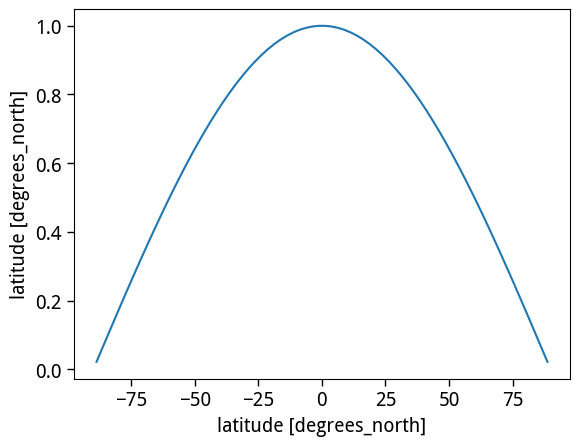

In [21]:
model_weights = np.cos(np.deg2rad(ts_ssp5_anom.lat))
model_weights.name = 'weights'
model_weights.plot()

In [22]:
ts_ssp5_det = funcs.detrend_rolling_window(ts_ssp5_anom, window_size=15)
pr_ssp5_det = funcs.detrend_rolling_window(pr_ssp5_anom, window_size=15)

In [23]:
nino34_ssp5 = ts_ssp5_det.ts.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(model_weights).mean(('lat', 'lon'))
pr_ssp5_std = pr_ssp5_det.pr/pr_ssp5_det.pr.std('time')

In [ ]:
gmst_cmip6 = ts_ssp5_anom.weighted(weights=model_weights).mean(('lat', 'lon'))
gmst_cmip6

<xarray.Dataset> Size: 99kB
Dimensions:  (time: 250, model: 47)
Coordinates:
  * time     (time) datetime64[ns] 2kB 1850-06-01 1851-06-01 ... 2099-06-01
  * model    (model) <U16 3kB 'CanESM5' 'CanESM5-CanOE' ... 'BCC-CSM2-MR'
Data variables:
    ts       (model, time) float64 94kB -0.3522 -0.3758 -0.3653 ... 4.134 4.248

In [ ]:
gmst_cmip6.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/cmip6/gmst_ssp5.nc')

### time-period division (only using 8.5 W/m2 forcing scenarios)

In [24]:
# out_baseline = funcs.get_all_metrics(nino34_ssp5.drop_sel(model = 'KIOST-ESM').sel(time = slice('1950', '2014')), pr_ssp5_std.sel(time = slice('1950', '2014')), dim='time')
out_baseline = funcs.get_all_metrics(nino34_ssp5.drop_sel(model = 'KIOST-ESM').sel(time = slice('1950', '2014')), ts_ssp5_det.ts.drop_sel(model = 'KIOST-ESM').sel(time = slice('1950', '2014')), dim='time')
out_baseline

(<xarray.DataArray 'ts' (model: 46, lat: 72, lon: 144)> Size: 4MB
 array([[[ 0.16278069,  0.15725656,  0.15083795, ...,  0.17155343,
           0.17006553,  0.16714413],
         [ 0.23988552,  0.233063  ,  0.22750752, ...,  0.24415231,
           0.24613765,  0.24557547],
         [ 0.32251884,  0.32089095,  0.313653  , ...,  0.28869626,
           0.30217779,  0.31528653],
         ...,
         [ 0.00559687, -0.00785186, -0.01745184, ...,  0.05808956,
           0.04523281,  0.02575113],
         [ 0.07463259,  0.06978621,  0.06524332, ...,  0.10671306,
           0.09512094,  0.08307452],
         [ 0.13076249,  0.13024814,  0.12896002, ...,  0.13057935,
           0.13209843,  0.13142454]],
 
        [[ 0.16278069,  0.15725656,  0.15083795, ...,  0.17155343,
           0.17006553,  0.16714413],
         [ 0.23988552,  0.233063  ,  0.22750752, ...,  0.24415231,
           0.24613765,  0.24557547],
         [ 0.32251884,  0.32089095,  0.313653  , ...,  0.28869626,
           0.30217

In [25]:
regr_baseline = xr.merge([out_baseline[0].to_dataset(name='regr'), out_baseline[1].to_dataset(name='corr'), out_baseline[2].to_dataset(name='pval')])

In [ ]:
# out_end_century = funcs.get_all_metrics(nino34_ssp5.drop_sel(model = 'KIOST-ESM').sel(time = slice('2070', '2100')), pr_ssp5_std.sel(time = slice('2070', '2100')), dim='time')
out_end_century = funcs.get_all_metrics(nino34_ssp5.drop_sel(model = 'KIOST-ESM').sel(time = slice('2070', '2100')), ts_ssp5_det.ts.drop_sel(model = 'KIOST-ESM').sel(time = slice('2070', '2100')), dim='time')

In [ ]:
regr_end_century = xr.merge([out_end_century[0].to_dataset(name='regr'), out_end_century[1].to_dataset(name='corr'), out_end_century[2].to_dataset(name='pval')])

In [28]:
# out_mid_century = funcs.get_all_metrics(nino34_ssp5.drop_sel(model = 'KIOST-ESM').sel(time = slice('2030', '2060')), pr_ssp5_std.sel(time = slice('2030', '2060')), dim='time')
out_mid_century = funcs.get_all_metrics(nino34_ssp5.drop_sel(model = 'KIOST-ESM').sel(time = slice('2030', '2060')), ts_ssp5_det.ts.drop_sel(model = 'KIOST-ESM').sel(time = slice('2030', '2060')), dim='time')

In [29]:
regr_mid_century = xr.merge([out_mid_century[0].to_dataset(name='regr'), out_mid_century[1].to_dataset(name='corr'), out_mid_century[2].to_dataset(name='pval')])

In [ ]:
regr_baseline.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_baseline.nc')
regr_end_century.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_end_century.nc')
regr_mid_century.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_mid_century.nc')

### GWL division (using all scenarios)

In [ ]:
out15 = funcs.get_all_metrics(nino34_ssp5.where((gmst_cmip6.ts > 1.4) & (gmst_cmip6.ts < 1.6)).drop_sel(model = 'KIOST-ESM'), ts_ssp5_det.ts.where((gmst_cmip6.ts > 1.4) & (gmst_cmip6.ts < 1.6)).drop_sel(model = 'KIOST-ESM'), dim='time')
regr15 = xr.merge([out15[0].to_dataset(name='regr'), out15[1].to_dataset(name='corr'), out15[2].to_dataset(name='pval')])

In [ ]:
out20 = funcs.get_all_metrics(nino34_ssp5.where((gmst_cmip6 > 1.9) & (gmst_cmip6 < 2.1)).drop_sel(model = 'KIOST-ESM'), ts_ssp5_det.ts.where((gmst_cmip6 > 1.9) & (gmst_cmip6 < 2.1)).drop_sel(model = 'KIOST-ESM'), dim='time')
regr20 = xr.merge([out20[0].to_dataset(name='regr'), out20[1].to_dataset(name='corr'), out20[2].to_dataset(name='pval')])

In [36]:
out30 = funcs.get_all_metrics(nino34_ssp5.where((gmst_cmip6.ts > 1.9) & (gmst_cmip6.ts < 3.1)).drop_sel(model = 'KIOST-ESM'), ts_ssp5_det.ts.where((gmst_cmip6.ts > 1.9) & (gmst_cmip6.ts < 3.1)).drop_sel(model = 'KIOST-ESM'), dim='time')
regr30 = xr.merge([out30[0].to_dataset(name='regr'), out30[1].to_dataset(name='corr'), out30[2].to_dataset(name='pval')])

In [37]:
# regr_baseline.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_baseline.nc')
regr15.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr15.nc')
regr20.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr20.nc')
regr30.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr30.nc')

In [45]:
out15 = funcs.get_all_metrics(nino34_ssp5.where((gmst_cmip6.ts > 1.4) & (gmst_cmip6.ts < 1.6)).drop_sel(model = 'KIOST-ESM'), pr_ssp5_std.where((gmst_cmip6.ts > 1.4) & (gmst_cmip6.ts < 1.6)), dim='time')
regr15 = xr.merge([out15[0].to_dataset(name='regr'), out15[1].to_dataset(name='corr'), out15[2].to_dataset(name='pval')])

In [46]:
out20 = funcs.get_all_metrics(nino34_ssp5.where((gmst_cmip6.ts > 1.4) & (gmst_cmip6.ts < 1.6)).drop_sel(model = 'KIOST-ESM'), pr_ssp5_std.where((gmst_cmip6.ts > 1.4) & (gmst_cmip6.ts < 1.6)), dim='time')
regr20 = xr.merge([out20[0].to_dataset(name='regr'), out20[1].to_dataset(name='corr'), out20[2].to_dataset(name='pval')])

In [47]:
out30 = funcs.get_all_metrics(nino34_ssp5.where((gmst_cmip6.ts > 1.4) & (gmst_cmip6.ts < 1.6)).drop_sel(model = 'KIOST-ESM'), pr_ssp5_std.where((gmst_cmip6.ts > 1.4) & (gmst_cmip6.ts < 1.6)), dim='time')
regr30 = xr.merge([out30[0].to_dataset(name='regr'), out30[1].to_dataset(name='corr'), out30[2].to_dataset(name='pval')])

In [48]:
# regr_baseline.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_baseline.nc')
regr15.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr15.nc')
regr20.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr20.nc')
regr30.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr30.nc')

### composites (all time and models, use gmst to get the)

In [53]:
en_composite = ts_ssp5_det.ts.where(nino34_ssp5 > nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
ln_composite = ts_ssp5_det.ts.where(nino34_ssp5 < -nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
neut_composite = ts_ssp5_det.ts.where((nino34_ssp5 > -0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')) & (nino34_ssp5 < 0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')))

In [54]:
composites = xr.merge([en_composite.to_dataset(name='en'), ln_composite.to_dataset(name = 'ln'), neut_composite.to_dataset(name='neut')])

In [55]:
composites.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts_enso_comp/cmip6_composites.nc')

In [49]:
en_composite = pr_ssp5_std.where(nino34_ssp5 > nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
ln_composite = pr_ssp5_std.where(nino34_ssp5 < -nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
neut_composite = pr_ssp5_std.where((nino34_ssp5 > -0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')) & (nino34_ssp5 < 0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')))

In [50]:
composites = xr.merge([en_composite.to_dataset(name='en'), ln_composite.to_dataset(name = 'ln'), neut_composite.to_dataset(name='neut')])

In [ ]:
composites.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/pr_enso_comp/cmip6_composites.nc')

In [27]:
composites

<xarray.Dataset> Size: 1GB
Dimensions:  (time: 250, model: 46, lon: 144, lat: 72)
Coordinates:
  * time     (time) datetime64[ns] 2kB 1850-06-01 1851-06-01 ... 2099-06-01
  * model    (model) <U16 3kB 'CanESM5' 'CanESM5-CanOE' ... 'BCC-CSM2-MR'
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * lat      (lat) float64 576B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
Data variables:
    en       (model, time, lat, lon) float32 477MB nan nan nan ... nan nan nan
    ln       (model, time, lat, lon) float32 477MB nan nan nan ... nan nan nan
    neut     (model, time, lat, lon) float32 477MB -0.4569 -0.4511 ... 0.6568

In [ ]:
# regr = funcs.get_all_metrics(nino34)